In [1]:
!pip install -q grad-cam gradio kagglehub seaborn scikit-learn

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import torch
import torchvision
import gradio as gr
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("DefectVision AI - Environment Check")
print("------------------------------------")
print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("Gradio:", gr.__version__)
print("OpenCV:", cv2.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Device:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU unavailable. Enable T4 GPU.")

print("\nEnvironment verification completed!")

DefectVision AI - Environment Check
------------------------------------
PyTorch: 2.14.1+cu130
TorchVision: 0.29.1+cu130
Gradio: 6.31.0
OpenCV: 4.14.0
GPU Available: True
GPU Device: Tesla T4

Environment verification completed!


In [3]:
import kagglehub
import os

print("Downloading NEU Surface Defect Dataset...")

dataset_path = kagglehub.dataset_download(
    "kaustubhdikshit/neu-surface-defect-database"
)

print("\nDataset downloaded successfully!")
print("Dataset location:", dataset_path)

Using Colab cache for faster access to the 'neu-surface-defect-database' dataset.

Dataset downloaded successfully!
Dataset location: /kaggle/input/neu-surface-defect-database


In [4]:
import os

print("DATASET DIRECTORY STRUCTURE")
print("=" * 50)

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:5]:
        print(f"{indent}    {file}")

    if len(files) > 5:
        print(f"{indent}    ... and {len(files)-5} more files")

DATASET DIRECTORY STRUCTURE
neu-surface-defect-database/
    NEU-DET/
        validation/
            annotations/
                scratches_246.xml
                patches_258.xml
                crazing_241.xml
                patches_267.xml
                crazing_270.xml
                ... and 356 more files
            images/
        train/
            annotations/
                patches_36.xml
                inclusion_147.xml
                crazing_200.xml
                rolled-in_scale_32.xml
                rolled-in_scale_61.xml
                ... and 1434 more files
            images/


In [5]:

import os
import glob
import xml.etree.ElementTree as ET
from collections import Counter

base_path = os.path.join(dataset_path, "NEU-DET")

for split in ["train", "validation"]:

    annotation_dir = os.path.join(base_path, split, "annotations")
    image_dir = os.path.join(base_path, split, "images")

    xml_files = glob.glob(os.path.join(annotation_dir, "*.xml"))

    image_files = []
    for ext in ["*.jpg", "*.jpeg", "*.png", "*.bmp"]:
        image_files.extend(
            glob.glob(os.path.join(image_dir, ext))
        )

    class_counts = Counter()
    total_boxes = 0

    for xml_file in xml_files:
        root = ET.parse(xml_file).getroot()

        for obj in root.findall("object"):
            class_name = obj.findtext("name", default="unknown")
            class_counts[class_name] += 1
            total_boxes += 1

    print(f"\n{'='*45}")
    print(f" SPLIT: {split.upper()}")
    print(f"{'='*45}")

    print("XML annotations:", len(xml_files))
    print("Image files:", len(image_files))
    print("Defect bounding boxes:", total_boxes)

    print("\nClass distribution:")
    for name, count in sorted(class_counts.items()):
        print(f"{name}: {count}")

    if xml_files:
        sample = ET.parse(xml_files[0]).getroot()

        print("\nSample annotation:")
        print("Filename:", sample.findtext("filename"))
        print("Image size:",
              sample.findtext("size/width"),
              "x",
              sample.findtext("size/height"))

        for obj in sample.findall("object"):
            print("Defect:", obj.findtext("name"))
            print("Bounding box:",
                  obj.findtext("bndbox/xmin"),
                  obj.findtext("bndbox/ymin"),
                  obj.findtext("bndbox/xmax"),
                  obj.findtext("bndbox/ymax"))



 SPLIT: TRAIN
XML annotations: 1439
Image files: 0
Defect bounding boxes: 3332

Class distribution:
crazing: 524
inclusion: 852
patches: 688
pitted_surface: 345
rolled-in_scale: 496
scratches: 427

Sample annotation:
Filename: patches_36.jpg
Image size: 200 x 200
Defect: patches
Bounding box: 16 101 70 135
Defect: patches
Bounding box: 109 5 164 199

 SPLIT: VALIDATION
XML annotations: 361
Image files: 0
Defect bounding boxes: 857

Class distribution:
crazing: 165
inclusion: 159
patches: 193
pitted_surface: 87
rolled-in_scale: 132
scratches: 121

Sample annotation:
Filename: scratches_246.jpg
Image size: 200 x 200
Defect: scratches
Bounding box: 2 157 180 171


In [6]:

import os
import glob

print("SEARCHING FOR IMAGE FILES")
print("=" * 55)

extensions = ["jpg", "jpeg", "png", "bmp", "JPG", "JPEG", "PNG"]

for split in ["train", "validation"]:

    split_path = os.path.join(base_path, split)

    print(f"\n{split.upper()}")

    for root, dirs, files in os.walk(split_path):

        image_files = [
            f for f in files
            if any(f.endswith("." + ext) for ext in extensions)
        ]

        if image_files:
            print("\nFolder:", root)
            print("Image count:", len(image_files))
            print("Sample files:", image_files[:5])

print("\n" + "=" * 55)
print("CHECKING ANNOTATION IMAGE PATH")

xml_file = glob.glob(
    os.path.join(base_path, "train", "annotations", "*.xml")
)[0]

import xml.etree.ElementTree as ET

root = ET.parse(xml_file).getroot()
filename = root.findtext("filename")

print("Expected image:", filename)

for folder, dirs, files in os.walk(dataset_path):
    if filename in files:
        print("FOUND IMAGE:", os.path.join(folder, filename))


SEARCHING FOR IMAGE FILES

TRAIN

Folder: /kaggle/input/neu-surface-defect-database/NEU-DET/train/images/inclusion
Image count: 240
Sample files: ['inclusion_1.jpg', 'inclusion_6.jpg', 'inclusion_28.jpg', 'inclusion_219.jpg', 'inclusion_11.jpg']

Folder: /kaggle/input/neu-surface-defect-database/NEU-DET/train/images/scratches
Image count: 240
Sample files: ['scratches_141.jpg', 'scratches_95.jpg', 'scratches_129.jpg', 'scratches_132.jpg', 'scratches_210.jpg']

Folder: /kaggle/input/neu-surface-defect-database/NEU-DET/train/images/pitted_surface
Image count: 240
Sample files: ['pitted_surface_37.jpg', 'pitted_surface_117.jpg', 'pitted_surface_21.jpg', 'pitted_surface_66.jpg', 'pitted_surface_114.jpg']

Folder: /kaggle/input/neu-surface-defect-database/NEU-DET/train/images/patches
Image count: 240
Sample files: ['patches_89.jpg', 'patches_131.jpg', 'patches_41.jpg', 'patches_163.jpg', 'patches_39.jpg']

Folder: /kaggle/input/neu-surface-defect-database/NEU-DET/train/images/crazing
Image 

In [7]:
import os
from torchvision import datasets

train_path = os.path.join(base_path, "train", "images")
test_path = os.path.join(base_path, "validation", "images")

# Load datasets
full_train_dataset = datasets.ImageFolder(train_path)
test_dataset = datasets.ImageFolder(test_path)

# Class information
classes = full_train_dataset.classes
num_classes = len(classes)

print("DATASET LOADED SUCCESSFULLY")
print("=" * 45)

print("Classes:", classes)
print("Number of classes:", num_classes)
print("Training images:", len(full_train_dataset))
print("Testing images:", len(test_dataset))

print("\nTraining class distribution:")

from collections import Counter

train_counts = Counter(
    label for _, label in full_train_dataset.samples
)

for class_name, label in full_train_dataset.class_to_idx.items():
    print(f"{class_name}: {train_counts[label]}")

print("\nTesting class distribution:")

test_counts = Counter(
    label for _, label in test_dataset.samples
)

for class_name, label in test_dataset.class_to_idx.items():
    print(f"{class_name}: {test_counts[label]}")

DATASET LOADED SUCCESSFULLY
Classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Number of classes: 6
Training images: 1440
Testing images: 360

Training class distribution:
crazing: 240
inclusion: 240
patches: 240
pitted_surface: 240
rolled-in_scale: 240
scratches: 240

Testing class distribution:
crazing: 60
inclusion: 60
patches: 60
pitted_surface: 60
rolled-in_scale: 60
scratches: 60


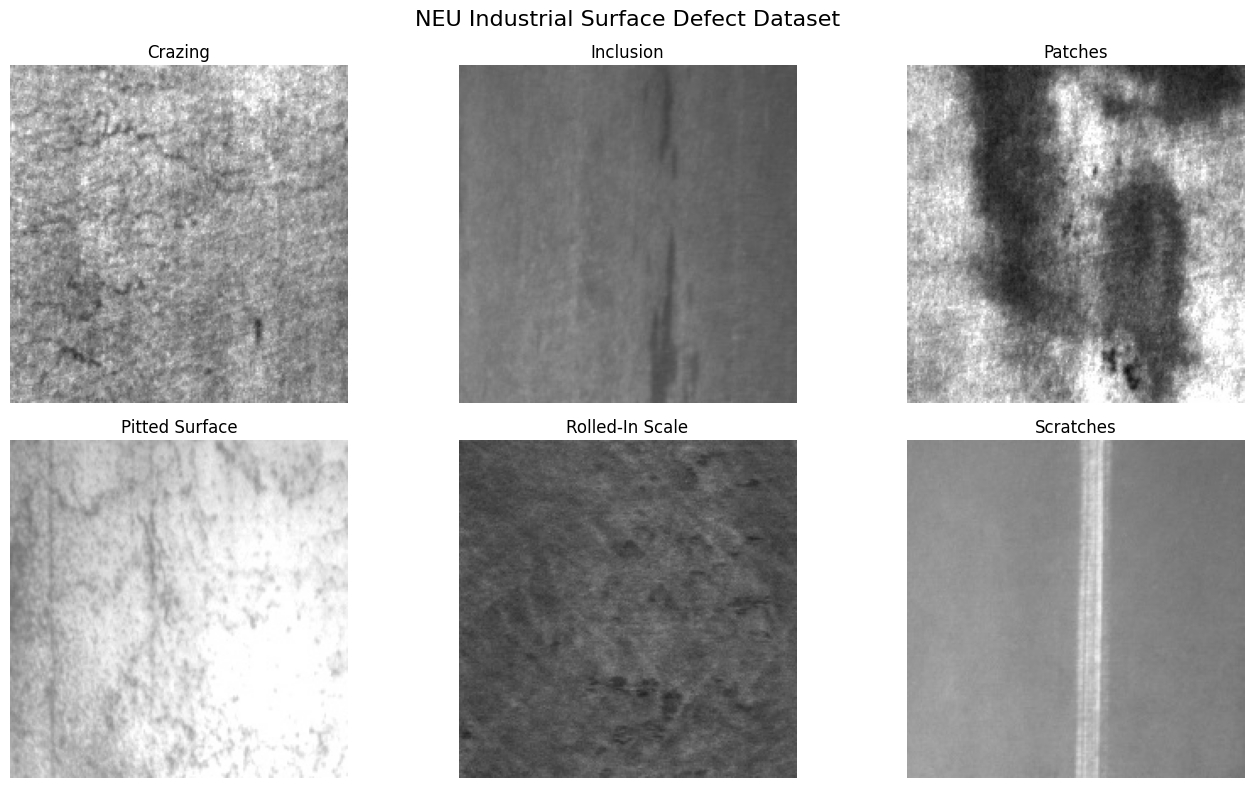

In [8]:
import matplotlib.pyplot as plt
from PIL import Image
import random

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for i, ax in enumerate(axes.flat):

    class_name = classes[i]

    class_images = [
        path for path, label in full_train_dataset.samples
        if label == i
    ]

    image_path = random.choice(class_images)

    img = Image.open(image_path).convert("RGB")

    ax.imshow(img)
    ax.set_title(class_name.replace("_", " ").title())
    ax.axis("off")

plt.suptitle(
    "NEU Industrial Surface Defect Dataset",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [9]:
import torch
import numpy as np

from torchvision import transforms, datasets
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [10]:
IMAGE_SIZE = 224
BATCH_SIZE = 32

# ImageNet normalization
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# Training transformations
train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Validation and testing transformations
test_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

print("Image transformations configured!")

Image transformations configured!


In [11]:
# Separate datasets for augmented and non-augmented images
train_full = datasets.ImageFolder(
    train_path,
    transform=train_transform
)

eval_full = datasets.ImageFolder(
    train_path,
    transform=test_transform
)

# Original class labels
labels = [label for _, label in train_full.samples]
indices = np.arange(len(labels))

# Stratified 80:20 split
train_indices, val_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEED,
    stratify=labels
)

# Create subsets
train_dataset = Subset(train_full, train_indices)
val_dataset = Subset(eval_full, val_indices)

# Official testing dataset
test_dataset = datasets.ImageFolder(
    test_path,
    transform=test_transform
)

print("DATASET SPLIT COMPLETED")
print("=" * 40)
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

DATASET SPLIT COMPLETED
Training: 1152
Validation: 288
Testing: 360


In [12]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# Verify a batch
images, labels_batch = next(iter(train_loader))

print("DATALOADER VERIFICATION")
print("=" * 40)
print("Image batch shape:", images.shape)
print("Label batch shape:", labels_batch.shape)
print("Image data type:", images.dtype)
print("Device:", device)

DATALOADER VERIFICATION
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Image data type: torch.float32
Device: cuda


In [13]:
import torch.nn as nn
from torchvision import models

# Load pretrained EfficientNet-B0
weights = models.EfficientNet_B0_Weights.DEFAULT

model = models.efficientnet_b0(weights=weights)

# Freeze pretrained feature extractor
for param in model.features.parameters():
    param.requires_grad = False

# Get number of input features
in_features = model.classifier[1].in_features

# Replace classification head
model.classifier = nn.Sequential(
    nn.Dropout(p=0.3),
    nn.Linear(in_features, num_classes)
)

# Move model to GPU
model = model.to(device)

print("DEFECTVISION AI MODEL")
print("=" * 45)
print("Architecture: EfficientNet-B0")
print("Pretrained weights: ImageNet")
print("Number of classes:", num_classes)
print("Classifier input features:", in_features)
print("Output classes:", classes)
print("Device:", device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("\nTotal parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 120MB/s]


DEFECTVISION AI MODEL
Architecture: EfficientNet-B0
Pretrained weights: ImageNet
Number of classes: 6
Classifier input features: 1280
Output classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Device: cuda

Total parameters: 4,015,234
Trainable parameters: 7,686


In [14]:
import torch.optim as optim

# Loss function
criterion = nn.CrossEntropyLoss(
    label_smoothing=0.05
)

# Optimizer
optimizer = optim.AdamW(
    model.classifier.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

# Learning rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

# Training configuration
EPOCHS_HEAD = 5

print("TRAINING CONFIGURATION")
print("=" * 40)
print("Epochs:", EPOCHS_HEAD)
print("Optimizer: AdamW")
print("Learning rate: 0.001")
print("Loss: CrossEntropyLoss")
print("Scheduler: ReduceLROnPlateau")

TRAINING CONFIGURATION
Epochs: 5
Optimizer: AdamW
Learning rate: 0.001
Loss: CrossEntropyLoss
Scheduler: ReduceLROnPlateau


In [15]:
model.eval()

with torch.no_grad():
    sample_images, sample_labels = next(iter(train_loader))

    sample_images = sample_images.to(device)

    outputs = model(sample_images)

print("MODEL VERIFICATION")
print("=" * 40)
print("Input shape:", sample_images.shape)
print("Output shape:", outputs.shape)
print("Expected output:", (BATCH_SIZE, num_classes))

assert outputs.shape == (BATCH_SIZE, num_classes)

print("\nModel architecture verified successfully!")

MODEL VERIFICATION
Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 6])
Expected output: (32, 6)

Model architecture verified successfully!


In [16]:

import copy
import time
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(loader, desc="Training", leave=False)

    for images, labels in progress:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        progress.set_postfix(loss=loss.item())

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


def validate_one_epoch(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


print("Training and validation functions defined!")


Training and validation functions defined!


In [17]:

EPOCHS = 5

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

best_val_accuracy = 0.0
best_model_weights = copy.deepcopy(model.state_dict())

print("STARTING DEFECTVISION AI TRAINING")
print("=" * 55)

start_time = time.time()

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_acc)
    history["val_accuracy"].append(val_acc)

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc*100:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc*100:.2f}%")

    if val_acc > best_val_accuracy:

        best_val_accuracy = val_acc
        best_model_weights = copy.deepcopy(model.state_dict())

        torch.save({
            "model_state_dict": best_model_weights,
            "classes": classes,
            "class_to_idx": full_train_dataset.class_to_idx,
            "best_val_accuracy": best_val_accuracy,
            "epoch": epoch + 1
        }, "/content/defectvision_best.pth")

        print("Best model checkpoint saved!")

elapsed = time.time() - start_time

model.load_state_dict(best_model_weights)

print("\n" + "=" * 55)
print("TRAINING COMPLETED")
print(f"Best validation accuracy: {best_val_accuracy*100:.2f}%")
print(f"Training time: {elapsed/60:.2f} minutes")
print("Best model restored.")


STARTING DEFECTVISION AI TRAINING

Epoch 1/5


Training:   0%|          | 0/36 [00:00<?, ?it/s]

Train Loss: 1.0902
Train Accuracy: 76.39%
Validation Loss: 0.7713
Validation Accuracy: 92.71%
Best model checkpoint saved!

Epoch 2/5


Training:   0%|          | 0/36 [00:00<?, ?it/s]

Train Loss: 0.5074
Train Accuracy: 94.88%
Validation Loss: 0.4775
Validation Accuracy: 96.18%
Best model checkpoint saved!

Epoch 3/5


Training:   0%|          | 0/36 [00:00<?, ?it/s]

... (2 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7deb839e1f80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7deb839e1f80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Train Loss: 0.3977
Train Accuracy: 96.61%
Validation Loss: 0.3777
Validation Accuracy: 97.57%
Best model checkpoint saved!

Epoch 5/5


Training:   0%|          | 0/36 [00:00<?, ?it/s]

Train Loss: 0.3834
Train Accuracy: 96.79%
Validation Loss: 0.3701
Validation Accuracy: 96.18%

TRAINING COMPLETED
Best validation accuracy: 97.57%
Training time: 1.19 minutes
Best model restored.


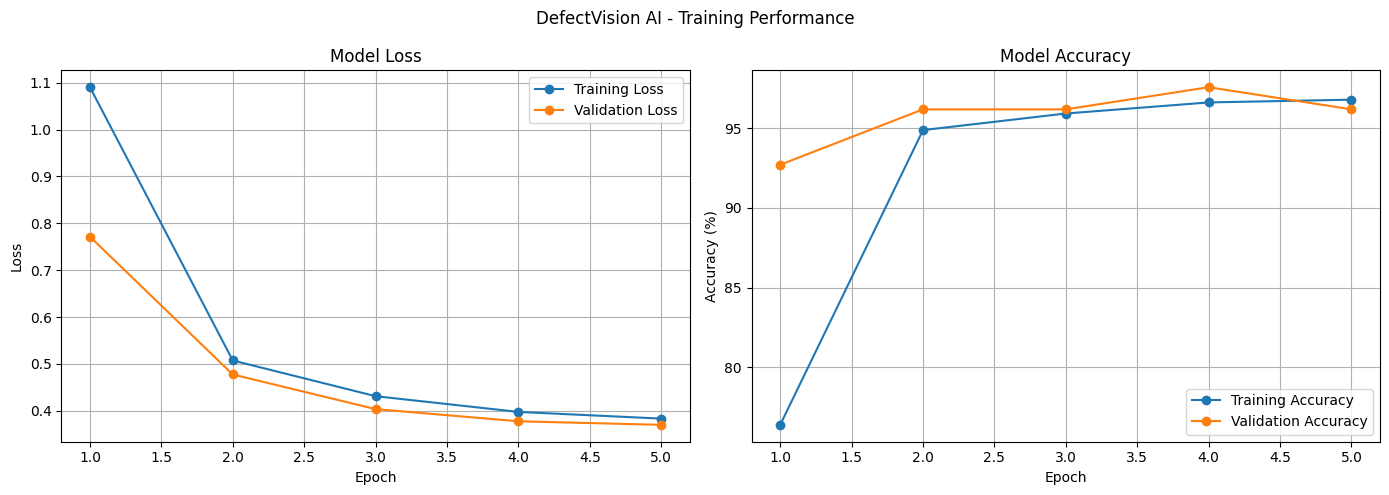

In [18]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs_range = range(1, len(history["train_loss"]) + 1)

# Loss graph
axes[0].plot(
    epochs_range,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

axes[0].plot(
    epochs_range,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

axes[0].set_title("Model Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Accuracy graph
axes[1].plot(
    epochs_range,
    [x * 100 for x in history["train_accuracy"]],
    marker="o",
    label="Training Accuracy"
)

axes[1].plot(
    epochs_range,
    [x * 100 for x in history["val_accuracy"]],
    marker="o",
    label="Validation Accuracy"
)

axes[1].set_title("Model Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

plt.suptitle("DefectVision AI - Training Performance")
plt.tight_layout()
plt.show()


In [19]:
from torch.utils.data import DataLoader

# Avoid multiprocessing issues in Colab
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Test DataLoader ready!")
print("Test images:", len(test_dataset))

Test DataLoader ready!
Test images: 360


In [20]:
import numpy as np
import torch

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

model.eval()

all_predictions = []
all_labels = []
all_probabilities = []

with torch.no_grad():

    for images, labels_batch in test_loader:

        images = images.to(device)

        outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels_batch.numpy()
        )

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)
all_probabilities = np.array(all_probabilities)

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

test_precision = precision_score(
    all_labels,
    all_predictions,
    average="macro"
)

test_recall = recall_score(
    all_labels,
    all_predictions,
    average="macro"
)

test_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro"
)

print("=" * 55)
print("DEFECTVISION AI - OFFICIAL TEST RESULTS")
print("=" * 55)

print(f"Test Accuracy : {test_accuracy*100:.2f}%")
print(f"Precision     : {test_precision*100:.2f}%")
print(f"Recall        : {test_recall*100:.2f}%")
print(f"Macro F1      : {test_f1*100:.2f}%")

print("\nCLASSIFICATION REPORT")

print(classification_report(
    all_labels,
    all_predictions,
    target_names=classes,
    digits=4
))

DEFECTVISION AI - OFFICIAL TEST RESULTS
Test Accuracy : 95.83%
Precision     : 96.34%
Recall        : 95.83%
Macro F1      : 95.80%

CLASSIFICATION REPORT
                 precision    recall  f1-score   support

        crazing     0.9677    1.0000    0.9836        60
      inclusion     0.9796    0.8000    0.8807        60
        patches     1.0000    0.9833    0.9916        60
 pitted_surface     1.0000    0.9833    0.9916        60
rolled-in_scale     1.0000    0.9833    0.9916        60
      scratches     0.8333    1.0000    0.9091        60

       accuracy                         0.9583       360
      macro avg     0.9634    0.9583    0.9580       360
   weighted avg     0.9634    0.9583    0.9580       360



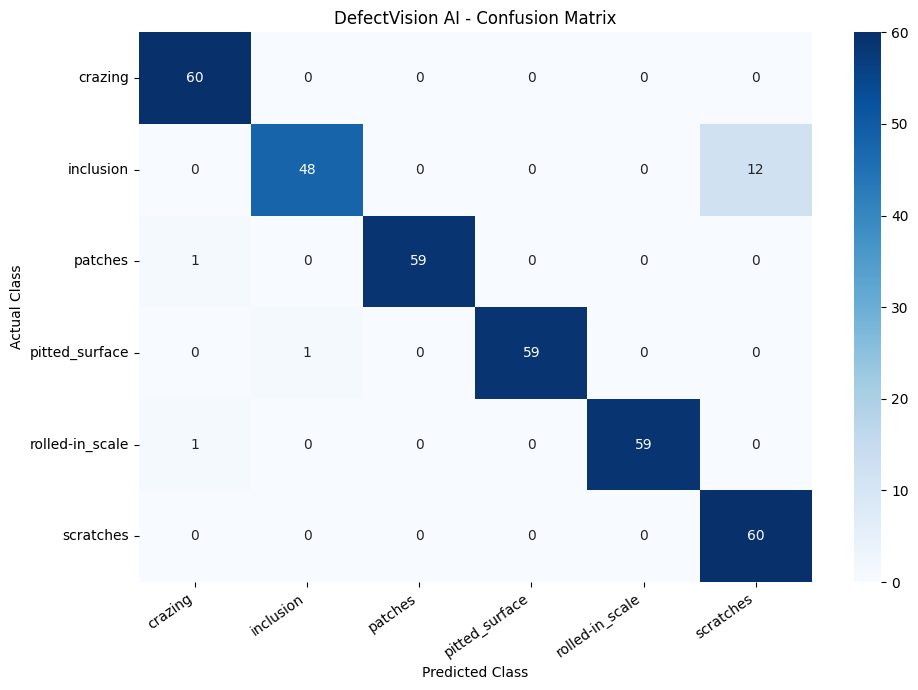

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("DefectVision AI - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plt.savefig(
    "/content/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import torch

# Select EfficientNet's final feature layer
target_layers = [model.features[-1]]

# Initialize Grad-CAM
cam = GradCAM(
    model=model,
    target_layers=target_layers
)

print("Grad-CAM initialized successfully!")

Grad-CAM initialized successfully!


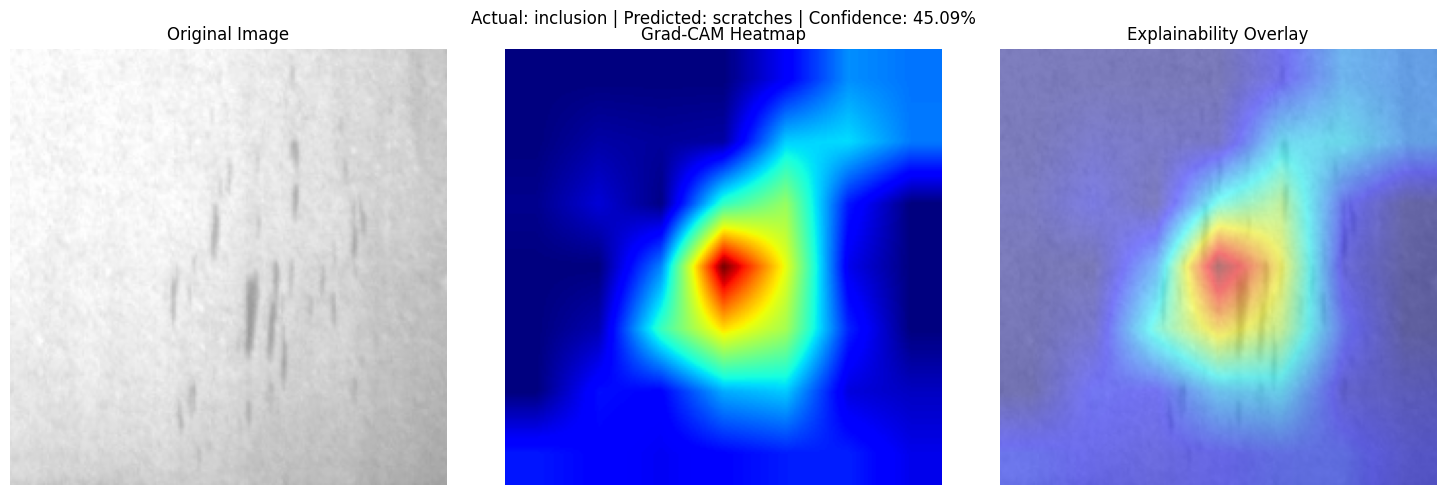

Grad-CAM generated successfully!
Actual class: inclusion
Predicted class: scratches
Confidence: 45.09%


In [24]:

import numpy as np
import matplotlib.pyplot as plt
import torch

from PIL import Image
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# Select an Inclusion -> Scratches misclassification
inclusion_idx = classes.index("inclusion")
scratches_idx = classes.index("scratches")

misclassified_indices = np.where(
    (all_labels == inclusion_idx) &
    (all_predictions == scratches_idx)
)[0]

if len(misclassified_indices) > 0:
    sample_idx = int(misclassified_indices[0])
else:
    sample_idx = 0

# Load original image
image_path, true_label = test_dataset.samples[sample_idx]

original_image = Image.open(image_path).convert("RGB")

rgb_image = np.array(
    original_image.resize((IMAGE_SIZE, IMAGE_SIZE))
)

# Prepare input tensor
input_tensor = (
    test_transform(original_image)
    .unsqueeze(0)
    .to(device)
)

# IMPORTANT: Enable gradient tracking
input_tensor.requires_grad_(True)

model.eval()

# Get prediction
with torch.no_grad():
    output = model(input_tensor.detach())

    probabilities = torch.softmax(output, dim=1)[0]

predicted_idx = int(probabilities.argmax().item())
confidence = float(probabilities[predicted_idx].item())

# Generate Grad-CAM with gradients enabled
targets = [
    ClassifierOutputTarget(predicted_idx)
]

with torch.enable_grad():

    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=targets
    )[0]

# Generate overlay
rgb_float = rgb_image.astype(np.float32) / 255.0

visualization = show_cam_on_image(
    rgb_float,
    grayscale_cam,
    use_rgb=True
)

# Display results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(rgb_image)
axes[0].set_title("Original Image")

axes[1].imshow(grayscale_cam, cmap="jet")
axes[1].set_title("Grad-CAM Heatmap")

axes[2].imshow(visualization)
axes[2].set_title("Explainability Overlay")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"Actual: {classes[true_label]} | "
    f"Predicted: {classes[predicted_idx]} | "
    f"Confidence: {confidence*100:.2f}%"
)

plt.tight_layout()

plt.savefig(
    "/content/gradcam_example.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Grad-CAM generated successfully!")
print("Actual class:", classes[true_label])
print("Predicted class:", classes[predicted_idx])
print("Confidence:", f"{confidence*100:.2f}%")


In [25]:
import gradio as gr
import cv2
import numpy as np
from PIL import Image

def analyze_defect(uploaded_image):

    if uploaded_image is None:
        raise gr.Error("Please upload an industrial surface image.")

    original = uploaded_image.convert("RGB")

    # Preprocess
    input_tensor = (
        test_transform(original)
        .unsqueeze(0)
        .to(device)
    )

    input_tensor.requires_grad_(True)

    model.eval()

    # Prediction
    with torch.no_grad():
        outputs = model(input_tensor.detach())
        probabilities = torch.softmax(outputs, dim=1)[0]

    predicted_idx = int(probabilities.argmax().item())
    confidence = float(probabilities[predicted_idx].item())

    # All class probabilities
    probability_dict = {
        classes[i].replace("_", " ").title():
        float(probabilities[i].item())
        for i in range(num_classes)
    }

    # Grad-CAM
    targets = [
        ClassifierOutputTarget(predicted_idx)
    ]

    with torch.enable_grad():
        grayscale_cam = cam(
            input_tensor=input_tensor,
            targets=targets
        )[0]

    # Resize original image
    rgb_image = np.array(
        original.resize((IMAGE_SIZE, IMAGE_SIZE))
    )

    rgb_float = rgb_image.astype(np.float32) / 255.0

    # Generate heatmap
    heatmap = cv2.applyColorMap(
        np.uint8(255 * grayscale_cam),
        cv2.COLORMAP_JET
    )

    heatmap = cv2.cvtColor(
        heatmap,
        cv2.COLOR_BGR2RGB
    )

    # Generate overlay
    overlay = show_cam_on_image(
        rgb_float,
        grayscale_cam,
        use_rgb=True
    )

    summary = (
        f"### Analysis completed\n"
        f"**Predicted defect:** "
        f"{classes[predicted_idx].replace('_', ' ').title()}\n\n"
        f"**Confidence:** {confidence * 100:.2f}%"
    )

    return (
        probability_dict,
        Image.fromarray(rgb_image),
        Image.fromarray(heatmap),
        Image.fromarray(overlay),
        summary
    )

print("DefectVision AI prediction pipeline ready!")

DefectVision AI prediction pipeline ready!


In [26]:
with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="emerald",
        secondary_hue="slate"
    )
) as demo:

    gr.Markdown(
        """
        # 🔬 DefectVision AI

        ### Intelligent Industrial Surface Inspection

        Upload a metal surface image to detect defects
        using Deep Learning and Explainable AI.
        """
    )

    with gr.Row():

        with gr.Column(scale=1):

            input_image = gr.Image(
                type="pil",
                label="Upload Surface Image"
            )

            analyze_btn = gr.Button(
                "🔍 Analyze Defect",
                variant="primary"
            )

        with gr.Column(scale=1):

            prediction = gr.Label(
                label="Defect Classification",
                num_top_classes=6
            )

            result_summary = gr.Markdown()

    gr.Markdown("---")

    gr.Markdown("## Visual Explainability")

    with gr.Row():

        original_output = gr.Image(
            label="Original Image"
        )

        heatmap_output = gr.Image(
            label="Grad-CAM Heatmap"
        )

        overlay_output = gr.Image(
            label="Explainability Overlay"
        )

    analyze_btn.click(
        fn=analyze_defect,
        inputs=input_image,
        outputs=[
            prediction,
            original_output,
            heatmap_output,
            overlay_output,
            result_summary
        ]
    )

    gr.Markdown(
        """
        ---
        **DefectVision AI** | Powered by PyTorch,
        EfficientNet-B0 and Grad-CAM.

        *AI-assisted surface inspection. Predictions
        should be verified by qualified inspectors.*
        """
    )

print("Frontend interface created!")

/tmp/ipykernel_427/4006874799.py:1: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Frontend interface created!


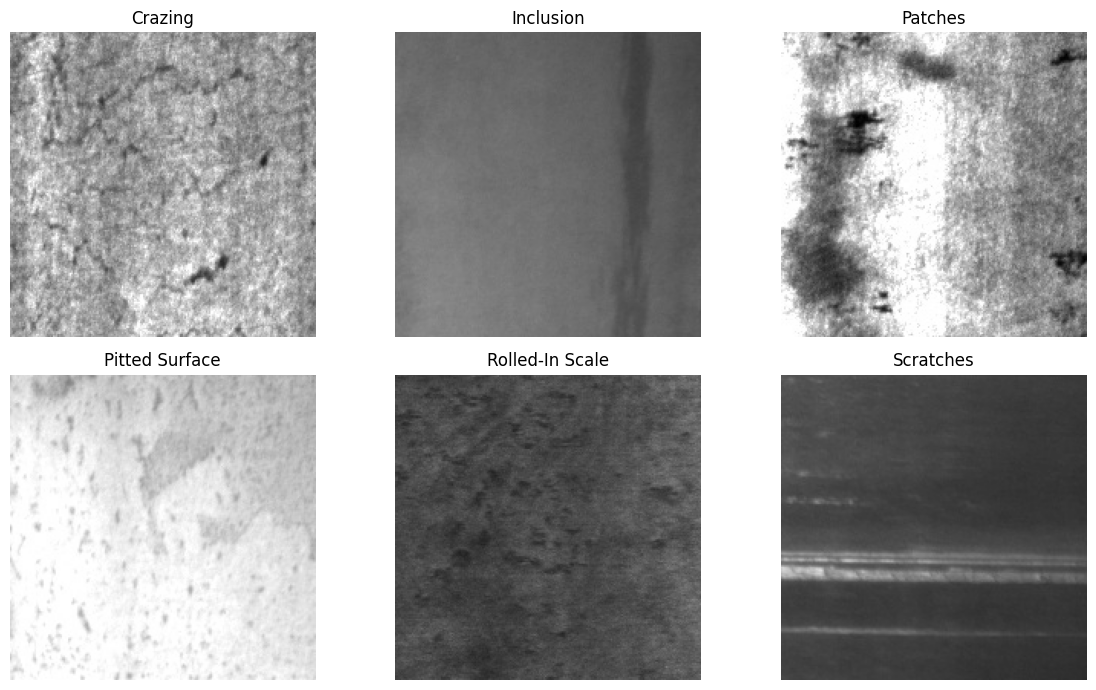

In [28]:
import random
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for i, ax in enumerate(axes.flat):
    paths = [
        path for path, label in test_dataset.samples
        if label == i
    ]

    path = random.choice(paths)
    img = Image.open(path).convert("RGB")

    ax.imshow(img)
    ax.set_title(classes[i].replace("_", " ").title())
    ax.axis("off")

plt.tight_layout()
plt.show()

In [27]:
demo.launch(
    share=True,
    debug=True
)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://a1f0816ca7592ac5c8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://a1f0816ca7592ac5c8.gradio.live


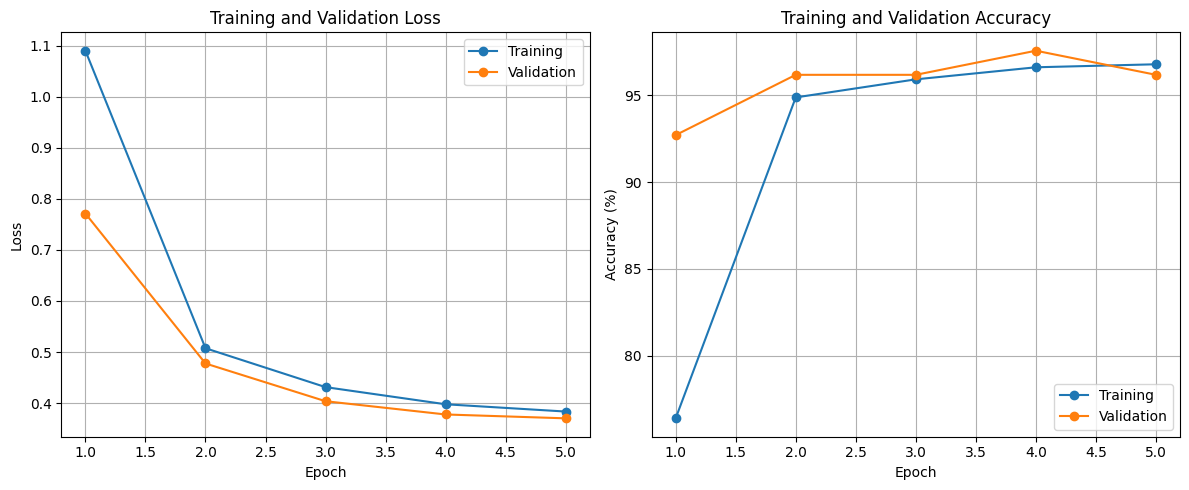

DEFECTVISION AI ARTIFACTS EXPORTED
.gitignore
requirements.txt
results/metrics.json
results/confusion_matrix.png
results/training_curves.png
results/gradcam_example.png
src/model_config.json
models/defectvision_best.pth

Project directory: /content/DefectVision-AI


In [29]:

import os
import json
import shutil
import torch
import matplotlib.pyplot as plt

PROJECT_DIR = "/content/DefectVision-AI"

# Create repository directories
folders = [
    "models",
    "results",
    "screenshots",
    "src",
    "notebook"
]

for folder in folders:
    os.makedirs(
        os.path.join(PROJECT_DIR, folder),
        exist_ok=True
    )

# Save trained model checkpoint
shutil.copy(
    "/content/defectvision_best.pth",
    os.path.join(PROJECT_DIR, "models", "defectvision_best.pth")
)

# Save confusion matrix
shutil.copy(
    "/content/confusion_matrix.png",
    os.path.join(PROJECT_DIR, "results", "confusion_matrix.png")
)

# Save Grad-CAM example
shutil.copy(
    "/content/gradcam_example.png",
    os.path.join(PROJECT_DIR, "results", "gradcam_example.png")
)

# Generate training curves
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

epochs_range = range(1, len(history["train_loss"]) + 1)

axes[0].plot(epochs_range, history["train_loss"], marker="o", label="Training")
axes[0].plot(epochs_range, history["val_loss"], marker="o", label="Validation")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    epochs_range,
    np.array(history["train_accuracy"]) * 100,
    marker="o",
    label="Training"
)

axes[1].plot(
    epochs_range,
    np.array(history["val_accuracy"]) * 100,
    marker="o",
    label="Validation"
)

axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(PROJECT_DIR, "results", "training_curves.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save evaluation metrics
metrics = {
    "test_accuracy": float(test_accuracy),
    "macro_precision": float(test_precision),
    "macro_recall": float(test_recall),
    "macro_f1": float(test_f1),
    "best_validation_accuracy": float(best_val_accuracy),
    "training_epochs": len(history["train_loss"]),
    "classes": classes,
    "test_images": len(test_dataset)
}

with open(
    os.path.join(PROJECT_DIR, "results", "metrics.json"),
    "w"
) as f:
    json.dump(metrics, f, indent=4)

# Save model configuration
config = {
    "architecture": "EfficientNet-B0",
    "pretrained": "ImageNet",
    "input_size": 224,
    "num_classes": num_classes,
    "classes": classes,
    "normalization_mean": mean,
    "normalization_std": std
}

with open(
    os.path.join(PROJECT_DIR, "src", "model_config.json"),
    "w"
) as f:
    json.dump(config, f, indent=4)

# Requirements
requirements = """
torch
torchvision
numpy
pandas
scikit-learn
matplotlib
seaborn
Pillow
opencv-python
streamlit
gradio
grad-cam
tqdm
kagglehub
"""

with open(
    os.path.join(PROJECT_DIR, "requirements.txt"),
    "w"
) as f:
    f.write(requirements.strip() + "\n")

# Git ignore
gitignore = """
__pycache__/
*.pyc
.venv/
venv/
.ipynb_checkpoints/
.DS_Store
"""

with open(
    os.path.join(PROJECT_DIR, ".gitignore"),
    "w"
) as f:
    f.write(gitignore.strip() + "\n")

print("=" * 50)
print("DEFECTVISION AI ARTIFACTS EXPORTED")
print("=" * 50)

for root, dirs, files in os.walk(PROJECT_DIR):
    for file in files:
        print(os.path.relpath(os.path.join(root, file), PROJECT_DIR))

print("\nProject directory:", PROJECT_DIR)


In [30]:
import shutil

shutil.make_archive(
    "/content/DefectVision-AI",
    "zip",
    "/content/DefectVision-AI"
)

print("Project ZIP created successfully!")


Project ZIP created successfully!


In [31]:
from google.colab import files

files.download("/content/DefectVision-AI.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>